# KO4 — High-scoring mutations cluster in core functional domains of PDAC driver genes

**AlphaMissense pathogenicity scores and protein domains**

This notebook tests **Key Objective 4**: that in the four canonical PDAC driver genes (KRAS, TP53,
SMAD4, CDKN2A), high-scoring AlphaMissense mutations are non-randomly distributed over protein
domains and preferentially cluster in core functional domains. Three complementary views are
presented: a whole-protein mutation density map, a per-residue AM score distribution by domain
class, and a 3D structural view of hotspot mutations, culminating in a domain × AM-class hotspot
summary table.


## Data

**Input**
- `merged_tcga_1000G.parquet` — TCGA-PAAD somatic (n=168 patients) + 1000 Genomes germline
  mutations, annotated with AlphaMissense scores.
- `alphamissense_hg38.parquet` — full AlphaMissense hg38 dataset (~71 M possible missense variants).
- `domain_annotations.yaml` — protein domain annotations for KRAS, TP53, SMAD4, CDKN2A with
  color scheme and AM colorbar configuration.
- AlphaFold v4 structures downloaded on-demand from the EBI API.

**Output**
- `../Figures/KO4_fig1_overview.{pdf,png}` — Figure 1: mutation density overview (2×2 panels)
- `../Figures/KO4_fig2_boxplot.{pdf,png}` — Figure 2: AM score distribution by domain class
- `figures/3D/KO4_fig3_3D.{pdf,png}` — Figure 3: 3D mutation landscape (2×2 grid)
- `figures/3D/{gene}_pub.{png,pse}` — individual gene renders + PyMOL sessions


## Method

- **Per-residue mean AM**: for each protein residue the mean AlphaMissense pathogenicity across all
  possible amino-acid substitutions (from `alphamissense_hg38.parquet`).
- **Domain classes**: residues assigned to one of four classes — Core Functional, Other PPI,
  Regulatory / Linker, Unclassified — using `domain_annotations.yaml`.
- **Kruskal-Wallis H test** across the four domain classes with Dunn's post-hoc pairwise test
  (Benjamini–Hochberg correction) from `scikit-posthocs`.
- **Hotspot**: a residue mutated in ≥ 2 individuals (PDAC somatic + healthy germline combined).
- **3D visualisation**: PyMOL cartoons (AlphaFold structures) with fixed-radius spheres at hotspot
  positions, coloured red = Pathogenic (AM ≥ 0.564), blue = Benign (AM < 0.34).
- **AlphaMissense thresholds**: Benign < 0.34 · Uncertain 0.34–0.564 · Pathogenic ≥ 0.564.


## Content

| # | Name | Description |
|---|------|-------------|
| 1 | Setup & Data Loading | Imports, constants, domain config, load datasets, compute all derived DataFrames |
| 2 | Figure 1 — Mutation Density Overview | 2×2 mutation count bars + AM gradient strip + domain track per driver gene |
| 3 | Figure 2 — Domain Class AM Distribution | Kruskal-Wallis + Dunn's; box plots of per-residue mean AM by domain class; sanity check |
| 4 | Figure 3 — 3D Mutation Landscape | PyMOL renders of hotspot mutations on AlphaFold structures; 2×2 publication grid |
| 5 | Table 1 — Hotspot Summary | Great Tables: hotspot count by gene × domain class × AM classification |


## 1. Setup & Data Loading


In [ ]:
import warnings
warnings.filterwarnings('ignore')

import pymol2
import polars as pl
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import Normalize, to_rgb
from matplotlib.cm import ScalarMappable
from matplotlib.patches import Patch, Rectangle
from matplotlib.lines import Line2D
import matplotlib.image as mpimg
import yaml
import re
import requests
from pathlib import Path
from scipy.stats import kruskal
import scikit_posthocs as sp
from great_tables import GT, md, style, loc
import seaborn as sns

sns.set_theme(style='whitegrid', context='paper', font_scale=1.1)
plt.rcParams.update({
    'font.family': 'sans-serif',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'axes.grid.axis': 'y',
    'grid.color': '#E0E0E0',
    'grid.linewidth': 0.7,
})

# Data paths (network drive → local fallback)
_NETWORK = Path('/zfsdata/BRP_DF/data')
_LOCAL   = Path('C:/2604_BRP/Data')
DATA_DIR   = _NETWORK if _NETWORK.exists() else _LOCAL
STRUCT_DIR = DATA_DIR / 'structures'
FIG_DIR    = DATA_DIR / 'figures/3D'
PUB_FIG_DIR = Path('../Figures')
STRUCT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)
PUB_FIG_DIR.mkdir(parents=True, exist_ok=True)

DRIVER_GENES = ['KRAS', 'TP53', 'SMAD4', 'CDKN2A']
UNIPROT_IDS  = {'KRAS': 'P01116', 'TP53': 'P04637', 'SMAD4': 'Q13485', 'CDKN2A': 'P42771'}
PROTEINS     = {
    'KRAS':   ('P01116', 189),
    'TP53':   ('P04637', 393),
    'SMAD4':  ('Q13485', 552),
    'CDKN2A': ('P42771', 156),
}

# Domain annotations — load from the Analyses folder (same directory as this notebook)
# NOTE: C:/2604_BRP/Data/domain_annotations.yaml is an older version with different colors;
#       the canonical file lives here, next to the notebook.
with open(Path('domain_annotations.yaml')) as f:
    domain_cfg = yaml.safe_load(f)

_cats         = domain_cfg['CATEGORIES']
DOMAIN_COLORS = {k: v['color'] for k, v in _cats.items()}
DOMAIN_LABELS = {k: v['display_label'] for k, v in _cats.items() if 'display_label' in v}
DOMAIN_COLORS_3D = DOMAIN_COLORS   # unified palette — no separate 3D version
BG_COLOR_3D      = '#AAAAAA'       # unannotated residues

CLASS_ORDER   = ['core_function', 'other_ppi', 'reg_linker', 'unclassified']
CLASS_DISPLAY = {
    'core_function': DOMAIN_LABELS.get('core_function', 'Core Functional'),
    'other_ppi':     DOMAIN_LABELS.get('other_ppi', 'Other PPI'),
    'reg_linker':    DOMAIN_LABELS.get('reg_linker', 'Regulatory / Linker'),
    'unclassified':  'Unclassified',
}

# AlphaMissense zone colors and thresholds (consistent with KO1/KO2/KO3)
_cfg_am       = domain_cfg['plot_config']['am_colorbar']
AM_CMAP       = _cfg_am['cmap']
AM_TICKS      = _cfg_am['ticks']
AM_TICKLABELS = _cfg_am['ticklabels']
AM_BENIGN_MAX = AM_TICKS[1]   # 0.34
AM_PATH_MIN   = AM_TICKS[2]   # 0.564
COLOR_BENIGN    = '#2065ab'
COLOR_UNCERTAIN = '#b1d5e7'
COLOR_PATH      = '#b1182b'
TCGA_COLOR  = domain_cfg['plot_config']['tcga_color']
G1000_COLOR = domain_cfg['plot_config']['g1000_color']

# PyMOL publication render constants
PUB_COLOR_PATH   = COLOR_PATH
PUB_COLOR_BENIGN = COLOR_BENIGN
PUB_SPHERE_SCALE = 0.6

# Fixed camera views obtained from interactive PyMOL sessions
GENE_VIEWS = {
    'KRAS': (
        0.747336328,   -0.656059265,    0.105196506,
        0.514653504,    0.671696603,    0.532874525,
        -0.420256883,   -0.344096333,    0.839630485,
        0.000100340,   -0.000068694, -174.845108032,
        -15.952891350,   -7.519215107,   10.673593521,
        78.383956909,  275.905090332,  -20.000000000,
    ),
    'TP53': (
        0.485797018,   -0.737968028,   -0.468378961,
        -0.873862326,   -0.421356469,  -0.242488340,
        -0.018403519,    0.527099550,  -0.849574506,
        -0.000049449,    0.000224784,  -340.520965576,
        5.753169060,    2.670461655,   -4.485670567,
    -502.582916260, 1187.673583984,    -20.000000000, 
    ),
    'SMAD4': (
        -0.325427860,   0.915982425,   0.234678686,
         0.448986262,  -0.068734795,   0.890889704,
         0.832168758,   0.395286709,  -0.388895333,
         0.000000000,   0.000000000, -353.873931885,
        -7.861328125,   1.524162292,   3.146476746,
       278.996887207, 428.750976562,  -20.000000000,
    ),
    'CDKN2A': (
         0.569891572,  -0.785275698,  -0.241983414,
         0.403785616,   0.011146154,   0.914780557,
        -0.715658426,  -0.619039953,   0.323438287,
         0.000000000,   0.000000000, -304.576934814,
         0.525726318,   3.619251251,  -1.907697678,
       239.644561768, 369.509277344,  -20.000000000,
    ),
}

print(f'Data directory : {DATA_DIR}')
print('Domain colour mapping:')
for k, v in DOMAIN_COLORS.items():
    print(f'  {k:<20} {v}   {DOMAIN_LABELS.get(k, "")}')


Data directory : C:\2604_BRP\Data
Domain colour mapping:
  core_function        #44AA99   Core Functional
  other_ppi            #EE8866   Other PPI
  reg_linker           #DDCC77   Regulatory / Linker


In [2]:
pl.Config.set_tbl_rows(-1)

# ── Raw data files ──────────────────────────────────────────────────────────
merged = pl.read_parquet(
    DATA_DIR / 'merged_tcga_1000G.parquet',
    columns=['gene_name', 'uniprot_id', 'protein_variant', 'source', 'am_pathogenicity'],
)
am_full = pl.read_parquet(
    DATA_DIR / 'alphamissense_hg38.parquet',
    columns=['uniprot_id', 'protein_variant', 'am_pathogenicity'],
)
uids        = [uid for uid, _ in PROTEINS.values()]
uid_to_gene = {uid: gene for gene, (uid, _) in PROTEINS.items()}
print(f'merged : {merged.height:,} rows')
print(f'am_full: {am_full.height:,} rows')

# ── Section 2 derivatives: AM gradient + mutation counts (Overview figure) ──
gene_to_uniprot_df = (
    merged
    .filter(pl.col('gene_name').is_in(DRIVER_GENES))
    .select(['gene_name', 'uniprot_id'])
    .drop_nulls()
    .group_by('gene_name')
    .agg(pl.col('uniprot_id').first())
    .to_dict(as_series=False)
)
gene_uniprot = dict(zip(gene_to_uniprot_df['gene_name'], gene_to_uniprot_df['uniprot_id']))

am_gradient = {}
print('\nBuilding AM gradient arrays:')
for gene, uid in gene_uniprot.items():
    sub = (
        am_full
        .filter(pl.col('uniprot_id') == uid)
        .with_columns(
            pl.col('protein_variant')
            .str.extract(r'(?:p\.)?[A-Za-z*](\d+)', group_index=1)
            .cast(pl.Int32)
            .alias('residue')
        )
        .drop_nulls('residue')
        .group_by('residue')
        .agg(pl.col('am_pathogenicity').mean().alias('mean_am'))
        .sort('residue')
    )
    max_res = sub['residue'].max()
    if max_res is None:
        am_gradient[gene] = np.array([])
        continue
    arr = np.full(max_res, np.nan)
    for row in sub.iter_rows(named=True):
        arr[row['residue'] - 1] = row['mean_am']
    am_gradient[gene] = arr
    print(f'  {gene}: {len(arr)} residues, {(~np.isnan(arr)).sum()} covered')

mut_df = (
    merged
    .filter(pl.col('gene_name').is_in(DRIVER_GENES))
    .with_columns(
        pl.col('protein_variant')
        .str.extract(r'(?:p\.)?[A-Za-z*](\d+)', group_index=1)
        .cast(pl.Int32)
        .alias('residue')
    )
    .drop_nulls('residue')
    .group_by(['gene_name', 'source', 'residue'])
    .agg(pl.len().alias('count'))
)
mut_counts = {g: {'TCGA': {}, '1000G': {}} for g in DRIVER_GENES}
for row in mut_df.iter_rows(named=True):
    src = 'TCGA' if 'TCGA' in row['source'] else '1000G'
    mut_counts[row['gene_name']][src][row['residue']] = row['count']
print('Mutation counts built.')

# ── Section 3 derivatives: per-residue mean AM + domain assignment ──────────
per_residue = (
    am_full
    .filter(pl.col('uniprot_id').is_in(uids))
    .with_columns(
        pl.col('protein_variant')
        .str.extract(r'(?:p\.)?[A-Za-z*](\d+)', group_index=1)
        .cast(pl.Int32)
        .alias('residue')
    )
    .drop_nulls('residue')
    .group_by(['uniprot_id', 'residue'])
    .agg(pl.col('am_pathogenicity').mean().alias('mean_am'))
    .drop_nulls('mean_am')
    .with_columns(
        pl.col('uniprot_id')
        .map_elements(lambda x: uid_to_gene[x], return_dtype=pl.String)
        .alias('gene')
    )
    .sort(['gene', 'residue'])
)

domain_rows_pr = []
for gene, (uid, prot_len) in PROTEINS.items():
    residue_map = {}
    for dom in domain_cfg.get(gene, []):
        for r in range(dom['start'], dom['end'] + 1):
            residue_map[r] = (dom['name'], dom['category'])
    for r in range(1, prot_len + 1):
        dn, dc = residue_map.get(r, (f'{gene}_unclassified', 'unclassified'))
        domain_rows_pr.append({
            'gene': gene, 'uniprot_id': uid, 'residue': r,
            'domain_name': dn, 'domain_class': dc,
        })

domain_df = pl.DataFrame(domain_rows_pr).with_columns(pl.col('residue').cast(pl.Int32))
annotated  = domain_df.join(
    per_residue.select(['uniprot_id', 'residue', 'mean_am']),
    on=['uniprot_id', 'residue'],
    how='left',
)
print(f'annotated: {annotated.height} residues, {annotated.drop_nulls("mean_am").height} with AM')

# ── Sections 4 & 5 derivatives: hotspot pipeline ────────────────────────────
df_parsed = (
    merged
    .filter(pl.col('gene_name').is_in(DRIVER_GENES))
    .with_columns(
        pl.col('protein_variant')
          .str.extract(r'(\d+)', 1)
          .cast(pl.Int64)
          .alias('aa_pos')
    )
    .drop_nulls('aa_pos')
)

df_pos = (
    df_parsed
    .group_by(['gene_name', 'aa_pos'])
    .agg([
        pl.col('am_pathogenicity').mean().round(4).alias('mean_am'),
        pl.len().alias('n_mutations'),
    ])
    .sort(['gene_name', 'aa_pos'])
)

df_counts_hs = (
    df_parsed
    .group_by(['gene_name', 'aa_pos', 'source'])
    .agg(pl.len().alias('n'))
    .pivot(index=['gene_name', 'aa_pos'], on='source', values='n')
)
for col in ['TCGA', '1000G']:
    if col not in df_counts_hs.columns:
        df_counts_hs = df_counts_hs.with_columns(pl.lit(0).cast(pl.Int64).alias(col))
df_counts_hs = (
    df_counts_hs
    .rename({'TCGA': 'n_PDAC', '1000G': 'n_Healthy'})
    .with_columns([
        pl.col('n_PDAC').fill_null(0),
        pl.col('n_Healthy').fill_null(0),
    ])
)

var_counts_df = (
    df_parsed
    .group_by(['gene_name', 'aa_pos', 'protein_variant'])
    .agg(pl.len().alias('n_var'))
    .sort(['gene_name', 'aa_pos', 'n_var'], descending=[False, False, True])
)
var_strings = {}
for row in var_counts_df.iter_rows(named=True):
    key = (row['gene_name'], row['aa_pos'])
    var_strings.setdefault(key, []).append(f"{row['protein_variant']}x{row['n_var']}")

df_var_list = pl.DataFrame([
    {'gene_name': k[0], 'aa_pos': k[1], 'variants': ', '.join(v)}
    for k, v in var_strings.items()
])

df_summary = (
    df_pos
    .join(df_counts_hs, on=['gene_name', 'aa_pos'], how='left')
    .join(df_var_list,  on=['gene_name', 'aa_pos'], how='left')
    .select(['gene_name', 'aa_pos', 'n_PDAC', 'n_Healthy', 'variants', 'mean_am'])
    .rename({'gene_name': 'Gene', 'aa_pos': 'Position', 'mean_am': 'Weighted AM'})
    .sort(['Gene', 'Position'])
)

def _classify_am(score: float) -> str:
    if score < AM_BENIGN_MAX:  return 'Benign'
    if score <= AM_PATH_MIN:   return 'Uncertain'
    return 'Pathogenic'

df_hotspots = (
    df_summary
    .with_columns((pl.col('n_PDAC') + pl.col('n_Healthy')).alias('n_total'))
    .filter(pl.col('n_total') >= 2)
    .with_columns(
        pl.col('Weighted AM')
          .map_elements(_classify_am, return_dtype=pl.String)
          .alias('AM Class')
    )
    .select(['Gene', 'Position', 'n_PDAC', 'n_Healthy', 'n_total', 'variants', 'Weighted AM', 'AM Class'])
    .sort(['Gene', 'n_total'], descending=[False, True])
)
print(f'Hotspot positions (n_total >= 2): {df_hotspots.height}')


merged : 32,078,948 rows
am_full: 71,697,556 rows

Building AM gradient arrays:
  TP53: 393 residues, 392 covered
  CDKN2A: 156 residues, 155 covered
  KRAS: 189 residues, 188 covered
  SMAD4: 552 residues, 551 covered
Mutation counts built.
annotated: 1290 residues, 1286 with AM
Hotspot positions (n_total >= 2): 39


## 2. Figure 1 — Mutation Density Overview

2×2 figure with one panel per driver gene. Each panel shows:
1. **Bar chart** — observed mutation counts per residue (TCGA-PAAD somatic vs 1000G germline)
2. **AM gradient strip** — mean AlphaMissense pathogenicity per residue (blue = benign → red = pathogenic)
3. **Domain track** — annotated protein domains from `domain_annotations.yaml`

TP53 uses a y-axis break because the R248 hotspot far exceeds the bulk distribution.


Saved: ..\Figures\KO4_fig1_overview.pdf


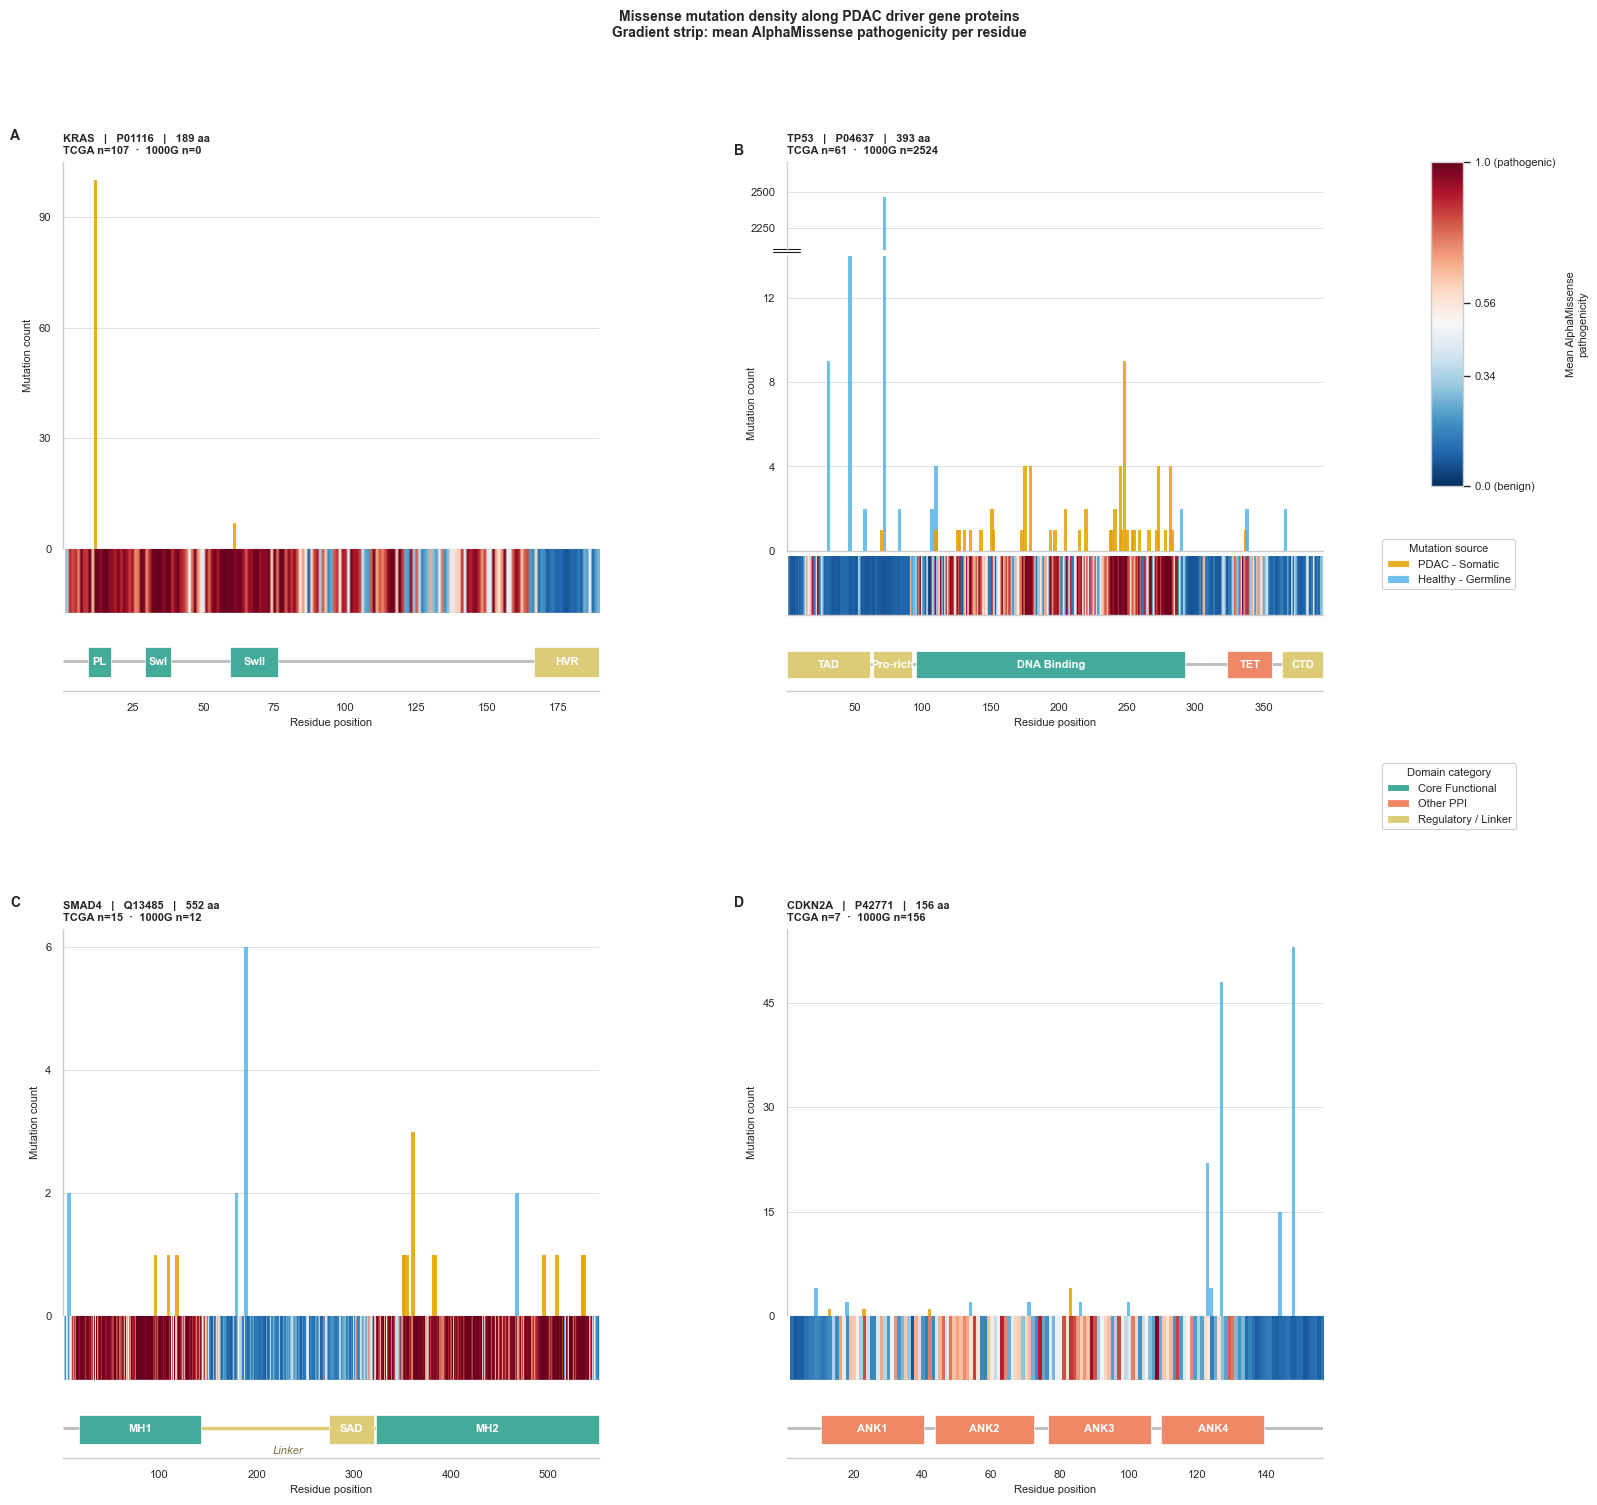

In [12]:
def _darken(color, factor=0.55):
    r, g, b = to_rgb(color)
    return (r * factor, g * factor, b * factor)


def compute_break(tcga_counts, g1000_counts, ratio=8):
    all_vals = list(tcga_counts.values()) + list(g1000_counts.values())
    if len(all_vals) < 2:
        return False, None, None
    max_val = max(all_vals)
    p95 = np.percentile(all_vals, 95)
    if p95 == 0 or max_val / p95 <= ratio:
        return False, None, None
    break_low  = int(np.ceil(p95 * 1.5))
    break_high = int(max_val * 0.85)
    return True, break_low, break_high


def draw_break_marks(ax_top, ax_bot, d=0.025, gap=0.015):
    kw = dict(color='k', clip_on=False, lw=0.8, transform=ax_top.transAxes)
    ax_top.plot((-d, +d), (0 - gap, 0 - gap), **kw)
    ax_top.plot((-d, +d), (0 + gap, 0 + gap), **kw)


_REF_LEN = min(length for _, length in PROTEINS.values())

def draw_bars(ax, tcga_counts, g1000_counts, all_residues, bar_width=1.0):
    for res in all_residues:
        cnt_t = tcga_counts.get(res, 0)
        cnt_g = g1000_counts.get(res, 0)
        if cnt_t >= cnt_g:
            ax.bar(res, cnt_t, width=bar_width, color=TCGA_COLOR,  alpha=0.85, zorder=3, linewidth=0)
            ax.bar(res, cnt_g, width=bar_width, color=G1000_COLOR, alpha=0.85, zorder=4, linewidth=0)
        else:
            ax.bar(res, cnt_g, width=bar_width, color=G1000_COLOR, alpha=0.85, zorder=3, linewidth=0)
            ax.bar(res, cnt_t, width=bar_width, color=TCGA_COLOR,  alpha=0.85, zorder=4, linewidth=0)


_SPINE_Y     = 0.38
_BLOCK_Y0    = 0.18
_BLOCK_H     = 0.38
_SPINE_LBL_Y = 0.03
_LABEL_Y     = 0.62
_LABEL_ROT   = 60
_LABEL_MIN   = 20

_FONT = 'Arial'
_FS   = 8


def draw_domain_track(ax, gene, prot_len):
    ax.hlines(_SPINE_Y, 0.5, prot_len + 0.5, colors='#BBBBBB', linewidth=2, zorder=1)

    for dom in domain_cfg.get(gene, []):
        if dom.get('render') != 'spine':
            continue
        color = dom.get('color', DOMAIN_COLORS.get(dom['category'], '#AAAAAA'))
        ax.hlines(_SPINE_Y, dom['start'] - 0.5, dom['end'] + 0.5,
                  colors=color, linewidth=2.5, zorder=2)
        mid = (dom['start'] + dom['end']) / 2
        ax.text(mid, _SPINE_LBL_Y, dom['name'],
                ha='center', va='bottom', fontsize=_FS, fontfamily=_FONT,
                color=_darken(color), fontstyle='italic', clip_on=True)

    for dom in domain_cfg.get(gene, []):
        if dom.get('render') == 'spine':
            continue
        color = dom.get('color', DOMAIN_COLORS.get(dom['category'], '#AAAAAA'))
        width = dom['end'] - dom['start'] + 1
        ax.broken_barh([(dom['start'] - 0.5, width)], (_BLOCK_Y0, _BLOCK_H),
                       facecolors=color, edgecolors='white', linewidth=0.5, zorder=3)
        mid = (dom['start'] + dom['end']) / 2
        display_text = dom.get('label', dom['name'])
        if width >= _LABEL_MIN or 'label' in dom:
            ax.text(mid, _BLOCK_Y0 + _BLOCK_H / 2, display_text,
                    ha='center', va='center', fontsize=_FS, fontfamily=_FONT,
                    color='white', fontweight='bold', clip_on=True)
        else:
            ax.text(mid, _LABEL_Y, display_text,
                    ha='left', va='bottom', fontsize=_FS, fontfamily=_FONT,
                    color='#222222', rotation=_LABEL_ROT,
                    rotation_mode='anchor', clip_on=False)

    ax.set_yticks([])
    ax.set_xlim(0.5, prot_len + 0.5)
    ax.set_ylim(0, 1)
    ax.spines[['top', 'right', 'left']].set_visible(False)
    ax.tick_params(axis='x', labelsize=_FS)


# ── Figure assembly ──────────────────────────────────────────────────────────
_GS_LEFT, _GS_RIGHT  = 0.08, 0.78
_GS_TOP,  _GS_BOTTOM = 0.88, 0.07
PANEL_LABELS = list('ABCD')

fig = plt.figure(figsize=(18, 16))
fig.patch.set_facecolor('white')
outer = gridspec.GridSpec(2, 2, figure=fig,
                          hspace=0.45, wspace=0.35,
                          left=_GS_LEFT, right=_GS_RIGHT,
                          top=_GS_TOP,   bottom=_GS_BOTTOM)

norm = Normalize(vmin=0, vmax=1)
sm   = ScalarMappable(cmap=AM_CMAP, norm=norm)
sm.set_array([])

for i, gene in enumerate(DRIVER_GENES):
    row, col = divmod(i, 2)

    gradient     = am_gradient[gene]
    tcga_counts  = mut_counts[gene]['TCGA']
    g1000_counts = mut_counts[gene]['1000G']
    all_residues = set(tcga_counts) | set(g1000_counts)
    prot_len     = len(gradient) if len(gradient) > 0 else (max(all_residues) if all_residues else 1)
    uid          = gene_uniprot.get(gene, '')
    n_tcga       = sum(tcga_counts.values())
    n_1000g      = sum(g1000_counts.values())
    needs_break, break_low, break_high = compute_break(tcga_counts, g1000_counts)
    bar_w = prot_len / _REF_LEN

    if needs_break:
        inner = gridspec.GridSpecFromSubplotSpec(
            4, 1, subplot_spec=outer[row, col],
            height_ratios=[1.5, 5, 1, 1.2], hspace=0.04
        )
        ax_upper = fig.add_subplot(inner[0])
        ax_lower = fig.add_subplot(inner[1], sharex=ax_upper)
        ax_strip = fig.add_subplot(inner[2], sharex=ax_upper)
        ax_dom   = fig.add_subplot(inner[3], sharex=ax_upper)

        draw_bars(ax_upper, tcga_counts, g1000_counts, all_residues, bar_width=bar_w)
        draw_bars(ax_lower, tcga_counts, g1000_counts, all_residues, bar_width=bar_w)

        max_val = max(max(tcga_counts.values(), default=0), max(g1000_counts.values(), default=0))
        ax_upper.set_ylim(break_high, max_val * 1.1)
        ax_lower.set_ylim(0, break_low)

        ax_upper.spines['bottom'].set_visible(False)
        ax_lower.spines['top'].set_visible(False)
        ax_upper.spines[['top', 'right']].set_visible(False)
        ax_lower.spines[['top', 'right']].set_visible(False)
        ax_upper.tick_params(axis='x', labelbottom=False, bottom=False)
        ax_upper.tick_params(axis='y', labelsize=_FS)
        ax_lower.yaxis.set_major_locator(plt.MaxNLocator(integer=True, nbins=4))
        draw_break_marks(ax_upper, ax_lower)

        ax_upper.set_title(
            f'{gene}   |   {uid}   |   {prot_len} aa\n'
            f'TCGA n={n_tcga}  ·  1000G n={n_1000g}',
            fontsize=_FS, fontweight='bold', pad=6, loc='left', fontfamily=_FONT,
        )
        ax_lower.set_ylabel('Mutation count', fontsize=_FS, fontfamily=_FONT)
        ax_lower.tick_params(axis='x', labelbottom=False, length=0)
        ax_lower.tick_params(axis='y', labelsize=_FS)

    else:
        inner = gridspec.GridSpecFromSubplotSpec(
            3, 1, subplot_spec=outer[row, col],
            height_ratios=[6, 1, 1.2], hspace=0
        )
        ax_lower = fig.add_subplot(inner[0])
        ax_strip = fig.add_subplot(inner[1], sharex=ax_lower)
        ax_dom   = fig.add_subplot(inner[2], sharex=ax_lower)

        draw_bars(ax_lower, tcga_counts, g1000_counts, all_residues, bar_width=bar_w)

        ax_lower.set_title(
            f'{gene}   |   {uid}   |   {prot_len} aa\n'
            f'TCGA n={n_tcga}  ·  1000G n={n_1000g}',
            fontsize=_FS, fontweight='bold', pad=6, loc='left', fontfamily=_FONT,
        )
        ax_lower.set_ylabel('Mutation count', fontsize=_FS, fontfamily=_FONT)
        ax_lower.spines[['top', 'right']].set_visible(False)
        ax_lower.tick_params(axis='x', labelbottom=False, length=0)
        ax_lower.tick_params(axis='y', labelsize=_FS)
        ax_lower.yaxis.set_major_locator(plt.MaxNLocator(integer=True, nbins=4))

    label_ax = ax_upper if needs_break else ax_lower
    label_ax.text(-0.08, 1.05, PANEL_LABELS[i],
                  transform=label_ax.transAxes,
                  fontsize=_FS + 2, fontweight='bold', va='bottom', ha='right',
                  fontfamily=_FONT)

    ax_lower.set_xlim(0.5, prot_len + 0.5)
    if len(gradient) > 0:
        ax_strip.imshow(
            gradient.reshape(1, -1), aspect='auto', cmap=AM_CMAP, vmin=0, vmax=1,
            extent=[0.5, prot_len + 0.5, 0, 1]
        )
    ax_strip.set_yticks([])
    ax_strip.spines[['top', 'right', 'left']].set_visible(False)
    ax_strip.set_xlim(0.5, prot_len + 0.5)
    ax_strip.tick_params(axis='x', labelbottom=False, length=0)

    draw_domain_track(ax_dom, gene, prot_len)
    ax_dom.set_xlabel('Residue position', fontsize=_FS, fontfamily=_FONT)

# Right-side legend area
_cb_h  = (_GS_TOP - _GS_BOTTOM) * 0.25
_leg_x = _GS_RIGHT + 0.03
_cb_x  = _leg_x + 0.03

cbar_ax = fig.add_axes([_cb_x, _GS_TOP - _cb_h, 0.018, _cb_h])
cb = fig.colorbar(sm, cax=cbar_ax)
cb.set_label('Mean AlphaMissense\npathogenicity', fontsize=_FS, labelpad=8, fontfamily=_FONT)
cb.set_ticks(AM_TICKS)
cb.set_ticklabels(AM_TICKLABELS, fontsize=_FS, fontfamily=_FONT)
cb.ax.tick_params(labelsize=_FS)

bar_handles = [
    Patch(facecolor=TCGA_COLOR,  alpha=0.85, label='PDAC - Somatic'),
    Patch(facecolor=G1000_COLOR, alpha=0.85, label='Healthy - Germline'),
]
fig.legend(
    handles=bar_handles, loc='upper left', ncol=1, fontsize=_FS,
    bbox_to_anchor=(_leg_x, _GS_TOP - _cb_h - 0.03),
    frameon=True, framealpha=0.95, edgecolor='#CCCCCC',
    title='Mutation source', title_fontsize=_FS,
    prop={'family': _FONT, 'size': _FS},
).get_title().set_fontfamily(_FONT)

dom_handles = [Patch(facecolor=DOMAIN_COLORS[k], label=v) for k, v in DOMAIN_LABELS.items()]
fig.legend(
    handles=dom_handles, loc='upper left', ncol=1, fontsize=_FS,
    bbox_to_anchor=(_leg_x, _GS_TOP - _cb_h - 0.17),
    frameon=True, framealpha=0.95, edgecolor='#CCCCCC',
    title='Domain category', title_fontsize=_FS,
    prop={'family': _FONT, 'size': _FS},
).get_title().set_fontfamily(_FONT)

fig.suptitle(
    'Missense mutation density along PDAC driver gene proteins\n'
    'Gradient strip: mean AlphaMissense pathogenicity per residue',
    fontsize=_FS + 2, y=0.975, fontweight='bold', fontfamily=_FONT,
)

fig.savefig(PUB_FIG_DIR / 'KO4_fig1_overview.pdf', dpi=300, bbox_inches='tight')
fig.savefig(PUB_FIG_DIR / 'KO4_fig1_overview.png', dpi=150, bbox_inches='tight')
with mpl.rc_context({'svg.fonttype': 'none'}):
    fig.savefig(PUB_FIG_DIR / 'KO4_fig1_overview.svg', bbox_inches='tight')
print(f'Saved: {PUB_FIG_DIR / "KO4_fig1_overview.pdf"}')
plt.show()


## 3. Figure 2 — AlphaMissense Score Distribution by Domain Class

Box plots of per-residue mean AlphaMissense pathogenicity, one row per domain class.
Preceded by a Kruskal-Wallis global test and Dunn's pairwise post-hoc (BH-corrected).
Followed by a sanity-check table of means and standard deviations (values used in the report).


In [13]:
from scipy.stats import bootstrap as _scipy_bootstrap

def _median_ci(data, confidence=0.95, n_resamples=4999, seed=0):
    res = _scipy_bootstrap(
        (np.asarray(data),), np.median,
        confidence_level=confidence,
        n_resamples=n_resamples,
        random_state=seed,
        method='percentile',
    )
    return res.confidence_interval.low, res.confidence_interval.high


data_by_class = {
    cls: annotated.drop_nulls('mean_am')
                  .filter(pl.col('domain_class') == cls)['mean_am']
                  .to_list()
    for cls in CLASS_ORDER
}

H, p_kw = kruskal(*data_by_class.values())
N    = sum(len(v) for v in data_by_class.values())
k    = len(data_by_class)
eps2 = (H - k + 1) / (N - k)

print(f'Kruskal-Wallis H({k-1}) = {H:.3f},  p = {p_kw:.2e},  ε² = {eps2:.3f}')

df_long = (
    annotated.drop_nulls('mean_am')
    .select(['domain_class', 'mean_am'])
    .to_pandas()
)
dunn_p = sp.posthoc_dunn(df_long, val_col='mean_am', group_col='domain_class', p_adjust='fdr_bh')
dunn_p = dunn_p.loc[CLASS_ORDER, CLASS_ORDER]

print('\nDunn post-hoc p-values (BH-corrected):')
print(dunn_p.round(4).to_string())


Kruskal-Wallis H(3) = 599.199,  p = 1.50e-129,  ε² = 0.465

Dunn post-hoc p-values (BH-corrected):
               core_function  other_ppi  reg_linker  unclassified
core_function            1.0     0.0000         0.0        0.0000
other_ppi                0.0     1.0000         0.0        0.2599
reg_linker               0.0     0.0000         1.0        0.0000
unclassified             0.0     0.2599         0.0        1.0000


Saved: ..\Figures\KO4_fig2_boxplot.pdf


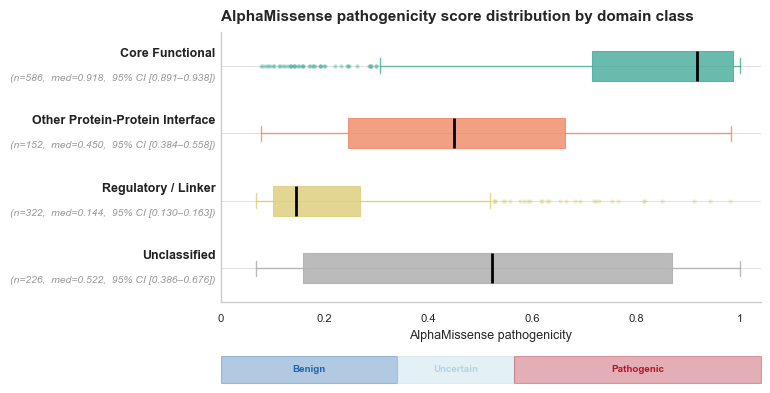

In [5]:
import matplotlib.transforms as mtransforms

data_groups_list = [data_by_class[cls] for cls in CLASS_ORDER]
box_colors = [DOMAIN_COLORS_3D.get(cls, BG_COLOR_3D) for cls in CLASS_ORDER]

# Pre-compute per-class stats for custom labels
_stats = {}
for cls in CLASS_ORDER:
    data = data_by_class[cls]
    _stats[cls] = {'n': len(data), 'med': np.median(data), 'ci': _median_ci(data)}

# Full label for "other_ppi" in this figure only
_fig_display = {**CLASS_DISPLAY, 'other_ppi': 'Other Protein-Protein Interface'}

fig_bp, ax_box = plt.subplots(1, 1, figsize=(9, 4.5))
fig_bp.patch.set_facecolor('white')
fig_bp.subplots_adjust(left=0.35, bottom=0.28, right=0.95, top=0.88)

bp = ax_box.boxplot(
    data_groups_list,
    vert=False,
    positions=range(len(CLASS_ORDER)),
    patch_artist=True,
    medianprops=dict(color='black', linewidth=2.0),
    widths=0.45,
)

for i, color in enumerate(box_colors):
    bp['boxes'][i].set(facecolor=color, edgecolor=color, alpha=0.80, linewidth=0.8)
    bp['medians'][i].set(color='black', linewidth=2.0)
    for wi in [2 * i, 2 * i + 1]:
        bp['whiskers'][wi].set(color=color, linewidth=1.0, alpha=0.80)
        bp['caps'][wi].set(color=color, linewidth=1.0, alpha=0.80)
    if i < len(bp['fliers']):
        bp['fliers'][i].set(markerfacecolor=color, markeredgecolor='none',
                            alpha=0.4, markersize=3)

# Suppress default tick labels; draw two-line custom labels instead
ax_box.set_yticks(range(len(CLASS_ORDER)))
ax_box.set_yticklabels([''] * len(CLASS_ORDER))
ax_box.set_ylim(-0.5, len(CLASS_ORDER) - 0.5)
ax_box.invert_yaxis()

# Blended transform: x in axes fraction, y in data coordinates
trans = mtransforms.blended_transform_factory(ax_box.transAxes, ax_box.transData)
for i, cls in enumerate(CLASS_ORDER):
    s = _stats[cls]
    ci_lo, ci_hi = s['ci']
    # Domain name — bold, dark
    ax_box.text(-0.01, i - 0.18, _fig_display[cls],
                transform=trans, ha='right', va='center',
                fontsize=9, fontweight='bold', color='#222222')
    # Stats — grey, italic, smaller
    ax_box.text(-0.01, i + 0.18,
                f'(n={s["n"]},  med={s["med"]:.3f},  95% CI [{ci_lo:.3f}–{ci_hi:.3f}])',
                transform=trans, ha='right', va='center',
                fontsize=7.5, color='#999999', style='italic')

ax_box.set_xlim(0, 1.04)
ax_box.set_xticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
ax_box.set_xticklabels(['0', '0.2', '0.4', '0.6', '0.8', '1'], fontsize=8)
ax_box.set_xlabel('AlphaMissense pathogenicity', fontsize=9)
ax_box.spines[['top', 'right']].set_visible(False)
ax_box.spines['left'].set_visible(True)
ax_box.set_title(
    'AlphaMissense pathogenicity score distribution by domain class',
    fontsize=11, fontweight='bold', loc='left', pad=8,
)

tr = ax_box.get_xaxis_transform()
y_bot, ht = -0.30, 0.10
zone_defs = [
    (0.0,           AM_BENIGN_MAX, COLOR_BENIGN,    'Benign'),
    (AM_BENIGN_MAX, AM_PATH_MIN,   COLOR_UNCERTAIN, 'Uncertain'),
    (AM_PATH_MIN,   1.04,          COLOR_PATH,      'Pathogenic'),
]
for x0, x1, color, label in zone_defs:
    ax_box.add_patch(Rectangle(
        (x0, y_bot), x1 - x0, ht,
        transform=tr, color=color, alpha=0.35, clip_on=False, zorder=2,
    ))
    ax_box.text((x0 + x1) / 2, y_bot + ht / 2, label,
                transform=tr, ha='center', va='center',
                fontsize=7, color=color, fontweight='bold', clip_on=False)

fig_bp.savefig(PUB_FIG_DIR / 'KO4_fig2_boxplot.pdf', dpi=300, bbox_inches='tight')
fig_bp.savefig(PUB_FIG_DIR / 'KO4_fig2_boxplot.png', dpi=150, bbox_inches='tight')
with mpl.rc_context({'svg.fonttype': 'none'}):
    fig_bp.savefig(PUB_FIG_DIR / 'KO4_fig2_boxplot.svg', bbox_inches='tight')
print(f'Saved: {PUB_FIG_DIR / "KO4_fig2_boxplot.pdf"}')
plt.show()


In [6]:
print('Per-class summary (residues with AM data):')
print(f'  {"Class":<20}  {"n":>5}  {"mean":>6}  {"sd":>6}  {"median":>7}  {"95% CI":>20}')
print(f'  {"-"*20}  {"-----":>5}  {"------":>6}  {"------":>6}  {"-------":>7}  {"--------------------":>20}')
total = 0
for cls in CLASS_ORDER:
    data  = annotated.drop_nulls('mean_am').filter(pl.col('domain_class') == cls)['mean_am'].to_numpy()
    n     = len(data)
    mean  = float(np.mean(data))   if n > 0 else float('nan')
    std   = float(np.std(data, ddof=1)) if n > 1 else float('nan')
    med   = float(np.median(data)) if n > 0 else float('nan')
    ci_lo, ci_hi = _median_ci(data) if n > 1 else (float('nan'), float('nan'))
    label = CLASS_DISPLAY.get(cls, cls)
    print(f'  {label:<20}  {n:>5}  {mean:>6.3f}  {std:>6.3f}  {med:>7.3f}  [{ci_lo:.3f}–{ci_hi:.3f}]')
    total += n
print(f'\n  Total: {total} residues across {len(DRIVER_GENES)} genes')


Per-class summary (residues with AM data):
  Class                     n    mean      sd   median                95% CI
  --------------------  -----  ------  ------  -------  --------------------
  Core Functional         586   0.805   0.247    0.918  [0.891–0.938]
  Other PPI               152   0.468   0.239    0.450  [0.384–0.558]
  Regulatory / Linker     322   0.221   0.182    0.144  [0.130–0.163]
  Unclassified            226   0.522   0.346    0.522  [0.386–0.676]

  Total: 1286 residues across 4 genes


## 4. Figure 3 — 3D Mutation Landscape

PyMOL renders of PDAC driver gene structures (AlphaFold v4) with hotspot mutations shown as
fixed-radius spheres: **red** = Pathogenic (AM ≥ 0.564), **blue** = Benign (AM < 0.34).
Uncertain hotspots are omitted. Domain colours match the unified palette.

Individual `.pse` session files are saved alongside PNGs and can be opened in PyMOL for
interactive exploration.


In [14]:
def hex_to_rgb(hex_color: str) -> list:
    h = hex_color.lstrip('#')
    return [int(h[i:i+2], 16) / 255.0 for i in (0, 2, 4)]


def am_to_rgb(score: float) -> list:
    cmap = plt.cm.RdBu_r
    return list(cmap(float(np.clip(score, 0.0, 1.0)))[:3])


def _pymol_env(cmd):
    cmd.bg_color('white')
    cmd.set('ray_opaque_background', 1)
    cmd.set('ray_shadows', 0)
    cmd.set('ambient', 0.50)
    cmd.set('direct', 0.70)
    cmd.set('specular', 0.20)


def _pymol_cartoon(cmd, gene: str):
    cmd.hide('everything', gene)
    cmd.show('cartoon', gene)
    cmd.set('cartoon_fancy_helices', 1)
    cmd.set('cartoon_smooth_loops', 1)
    cmd.set('cartoon_tube_radius', 0.4)


def _pymol_domain_colors(cmd, gene: str):
    bg_cname = f'{gene}_bg'
    cmd.set_color(bg_cname, hex_to_rgb(BG_COLOR_3D))
    cmd.color(bg_cname, gene)
    for category in ['reg_linker', 'other_ppi', 'core_function']:
        if category not in DOMAIN_COLORS_3D:
            continue
        cname = f'dom_{gene}_{category}'
        cmd.set_color(cname, hex_to_rgb(DOMAIN_COLORS_3D[category]))
        for dom in domain_cfg[gene]:
            if dom['category'] == category:
                cmd.color(cname, f'{gene} and resi {dom["start"]}-{dom["end"]}')


def _pymol_orient_save(cmd, gene: str, out_png: Path, rotate_y: float):
    if gene in GENE_VIEWS:
        cmd.set_view(GENE_VIEWS[gene])
    else:
        cmd.orient(gene)
        if rotate_y != 0.0:
            cmd.rotate('y', rotate_y)
        cmd.zoom(gene, buffer=2.0)
    cmd.ray(2400, 1800)
    cmd.png(str(out_png), dpi=300)


def render_publication(gene: str, rotate_y: float = 0.0) -> Path:
    suffix  = f'_rot{int(rotate_y)}' if rotate_y != 0.0 else ''
    out_png = FIG_DIR / f'{gene}_pub{suffix}.png'
    out_pse = FIG_DIR / f'{gene}_pub{suffix}.pse'

    gene_hotspots = df_hotspots.filter(pl.col('Gene') == gene).to_dicts()

    with pymol2.PyMOL() as pymol:
        cmd = pymol.cmd
        cmd.load(str(struct_paths[gene]), gene)
        cmd.remove('solvent')
        _pymol_env(cmd)
        _pymol_domain_colors(cmd, gene)
        _pymol_cartoon(cmd, gene)

        for row in gene_hotspots:
            if row['AM Class'] == 'Uncertain':
                continue
            pos   = row['Position']
            color = PUB_COLOR_PATH if row['AM Class'] == 'Pathogenic' else PUB_COLOR_BENIGN
            cname = f'pub_{gene}_{pos}'
            sname = f'pubspot_{gene}_{pos}'
            cmd.set_color(cname, hex_to_rgb(color))
            cmd.select(sname, f'{gene} and resi {pos} and name CA')
            cmd.show('spheres', sname)
            cmd.set('sphere_scale', PUB_SPHERE_SCALE, sname)
            cmd.color(cname, sname)

        _pymol_orient_save(cmd, gene, out_png, rotate_y)
        cmd.save(str(out_pse))

    return out_png


In [15]:
def download_alphafold(uniprot_id: str) -> Path:
    api_url = f'https://alphafold.ebi.ac.uk/api/prediction/{uniprot_id}'
    meta = requests.get(api_url, timeout=30)
    meta.raise_for_status()
    pdb_url = meta.json()[0]['pdbUrl']
    dest = STRUCT_DIR / Path(pdb_url).name
    if dest.exists():
        print(f'  Already exists : {dest.name}')
    else:
        print(f'  Downloading {dest.name} ...', end=' ', flush=True)
        r = requests.get(pdb_url, timeout=60)
        r.raise_for_status()
        dest.write_bytes(r.content)
        print('done')
    return dest


print('AlphaFold structures:')
struct_paths = {}
for gene, uid in UNIPROT_IDS.items():
    struct_paths[gene] = download_alphafold(uid)

pub_rendered = {}
print('\nRendering publication figures (skip if PNG already exists):')
for gene in DRIVER_GENES:
    out_png = FIG_DIR / f'{gene}_pub.png'
    if not out_png.exists():
        print(f'  {gene} ...', end=' ', flush=True)
        pub_rendered[gene] = render_publication(gene)
        print('done')
    else:
        pub_rendered[gene] = out_png
        print(f'  {gene}: skipped (PNG exists)')

print('\nAll renders complete. Open .pse files in PyMOL for interactive exploration.')


AlphaFold structures:
  Already exists : AF-P01116-F1-model_v6.pdb
  Already exists : AF-P04637-F1-model_v6.pdb
  Already exists : AF-Q13485-F1-model_v6.pdb
  Already exists : AF-P42771-F1-model_v6.pdb

Rendering publication figures (skip if PNG already exists):
  KRAS: skipped (PNG exists)
  TP53: skipped (PNG exists)
  SMAD4: skipped (PNG exists)
  CDKN2A: skipped (PNG exists)

All renders complete. Open .pse files in PyMOL for interactive exploration.


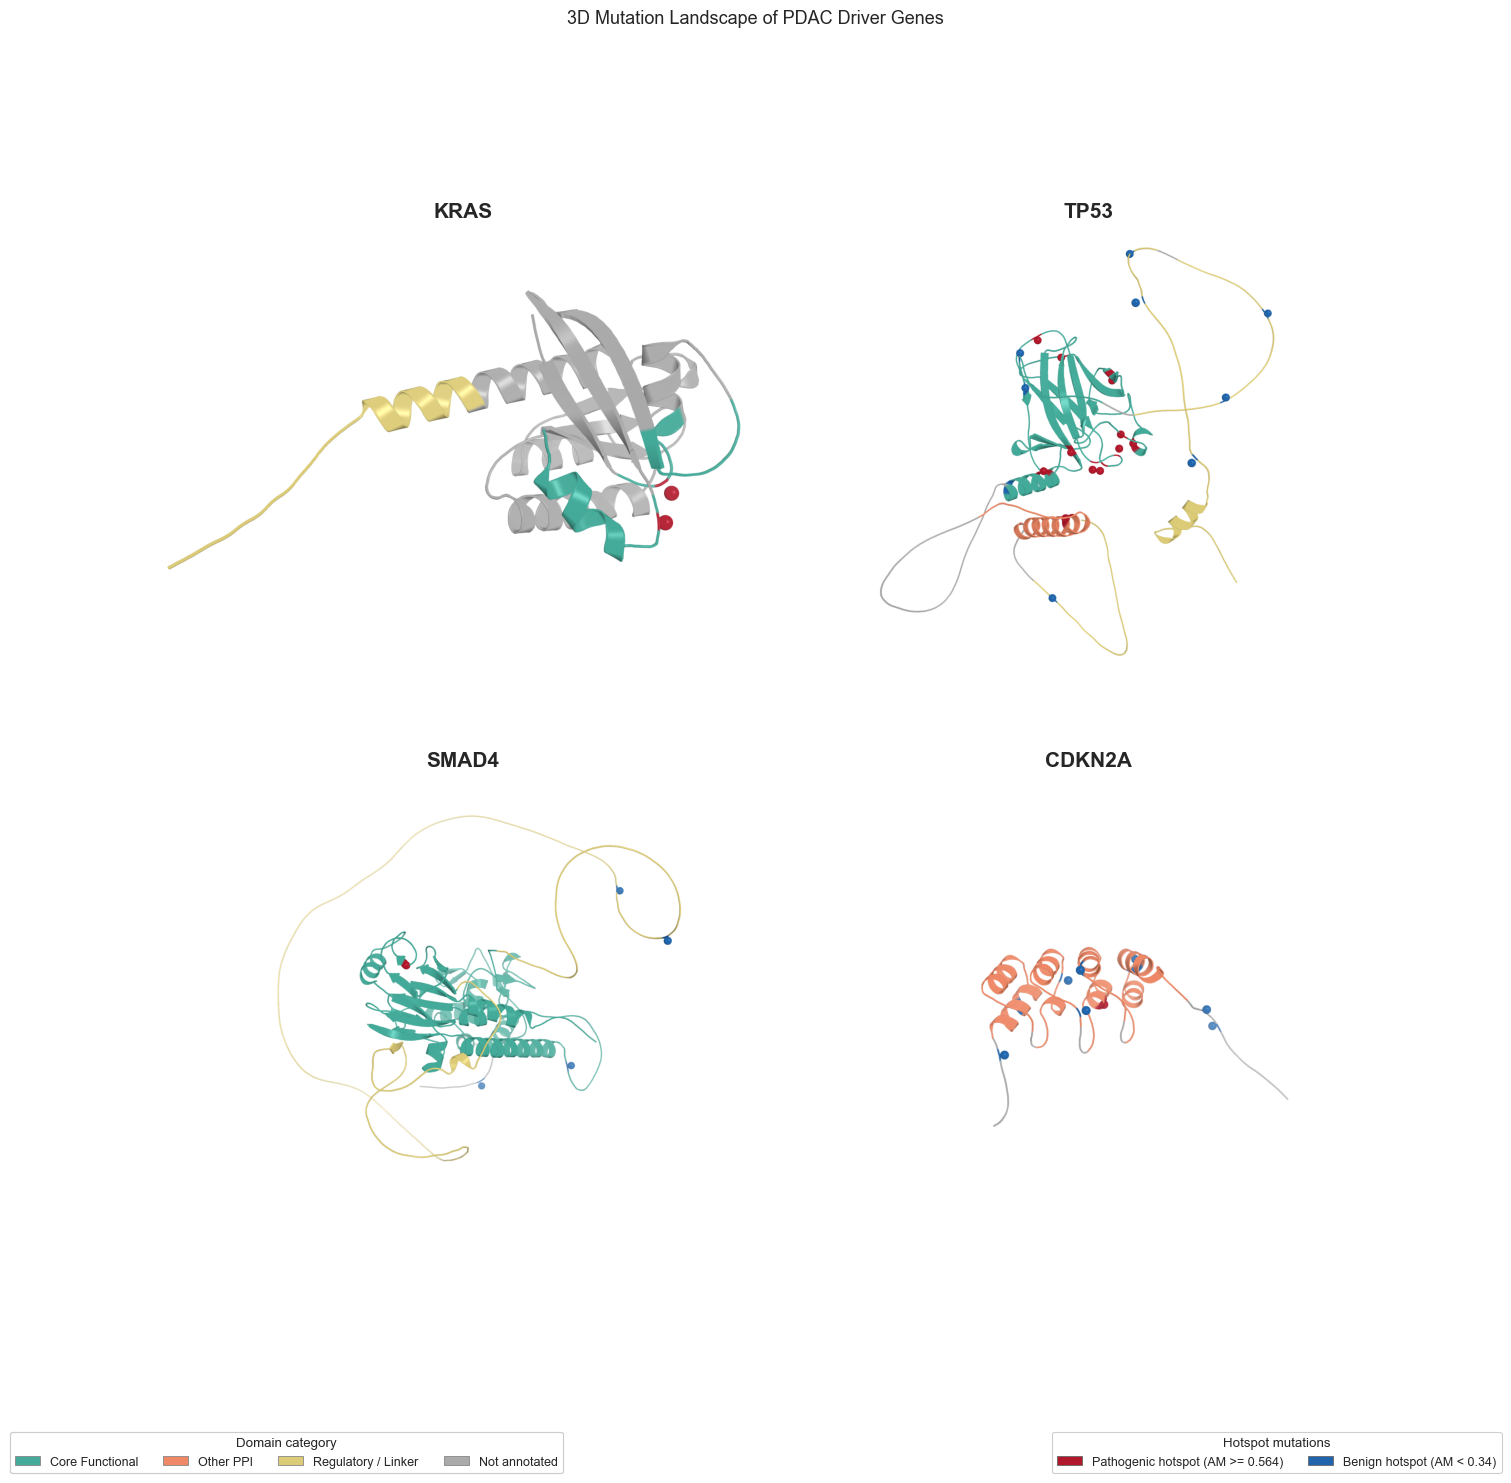

Saved: C:\2604_BRP\Data\figures\3D\KO4_fig3_3D.png


In [16]:
GENE_GRID = [['KRAS', 'TP53'], ['SMAD4', 'CDKN2A']]

fig_3d, axes = plt.subplots(2, 2, figsize=(16, 14),
                             gridspec_kw={'wspace': 0.02, 'hspace': 0.04})
fig_3d.patch.set_facecolor('white')

for row_idx, row_genes in enumerate(GENE_GRID):
    for col_idx, gene in enumerate(row_genes):
        ax = axes[row_idx, col_idx]
        ax.imshow(mpimg.imread(str(pub_rendered[gene])), aspect='equal')
        ax.axis('off')
        ax.set_title(gene, fontsize=15, fontweight='bold', pad=6)

_cat_labels = {k: domain_cfg['CATEGORIES'].get(k, {}).get('display_label', k)
               for k in DOMAIN_COLORS_3D}
domain_patches = [
    Patch(facecolor=DOMAIN_COLORS_3D['core_function'], edgecolor='#888', linewidth=0.6,
          label=_cat_labels['core_function']),
    Patch(facecolor=DOMAIN_COLORS_3D['other_ppi'],     edgecolor='#888', linewidth=0.6,
          label=_cat_labels['other_ppi']),
    Patch(facecolor=DOMAIN_COLORS_3D['reg_linker'],    edgecolor='#888', linewidth=0.6,
          label=_cat_labels['reg_linker']),
    Patch(facecolor=BG_COLOR_3D,                       edgecolor='#888', linewidth=0.6,
          label='Not annotated'),
]
mut_patches = [
    Patch(facecolor=PUB_COLOR_PATH,   edgecolor='#666', linewidth=0.6,
          label='Pathogenic hotspot (AM >= 0.564)'),
    Patch(facecolor=PUB_COLOR_BENIGN, edgecolor='#666', linewidth=0.6,
          label='Benign hotspot (AM < 0.34)'),
]

leg1 = fig_3d.legend(
    handles=domain_patches,
    loc='lower left', bbox_to_anchor=(0.03, -0.04),
    frameon=True, framealpha=0.95, edgecolor='#CCCCCC',
    fontsize=9, title='Domain category', title_fontsize=9.5,
    ncol=4,
)
fig_3d.add_artist(leg1)
fig_3d.legend(
    handles=mut_patches,
    loc='lower right', bbox_to_anchor=(0.97, -0.04),
    frameon=True, framealpha=0.95, edgecolor='#CCCCCC',
    fontsize=9, title='Hotspot mutations', title_fontsize=9.5,
    ncol=2,
)

fig_3d.suptitle('3D Mutation Landscape of PDAC Driver Genes', fontsize=13, y=1.01)

out_3d = FIG_DIR / 'KO4_fig3_3D.png'
fig_3d.savefig(str(out_3d), dpi=300, bbox_inches='tight', facecolor='white')
fig_3d.savefig(str(FIG_DIR / 'KO4_fig3_3D.pdf'), dpi=300, bbox_inches='tight', facecolor='white')
with mpl.rc_context({'svg.fonttype': 'none'}):
    fig_3d.savefig(str(FIG_DIR / 'KO4_fig3_3D.svg'), bbox_inches='tight', facecolor='white')
plt.show()
print(f'Saved: {out_3d}')


## 5. Table 1 — Hotspot Mutations by Domain Class

Great Tables summary: hotspot positions (n ≥ 2 individuals) per gene, domain class, and AM
classification. Layout: Benign columns left · Pathogenic columns right · Pathogenic hotspot
positions at far right. Uncertain AM class excluded; domain cells in the Total row are empty.


In [17]:
# Build position -> domain_class lookup and df_hs_dom
domain_rows_hs = []
for gene in DRIVER_GENES:
    residue_map = {}
    for dom in domain_cfg.get(gene, []):
        for r in range(dom['start'], dom['end'] + 1):
            residue_map[r] = dom['category']
    for row in df_hotspots.filter(pl.col('Gene') == gene).iter_rows(named=True):
        if row['AM Class'] == 'Uncertain':
            continue
        dc = residue_map.get(row['Position'], 'unclassified')
        domain_rows_hs.append({
            'Gene': gene, 'Position': row['Position'],
            'variants': row['variants'],
            'domain_class': dc, 'AM Class': row['AM Class'],
        })

df_hs_dom = pl.DataFrame(domain_rows_hs) if domain_rows_hs else pl.DataFrame(
    {'Gene': pl.Series([], dtype=pl.String),
     'Position': pl.Series([], dtype=pl.Int64),
     'variants': pl.Series([], dtype=pl.String),
     'domain_class': pl.Series([], dtype=pl.String),
     'AM Class': pl.Series([], dtype=pl.String)})

def _res_label(variants_str: str, pos: int) -> str:
    if variants_str:
        first = variants_str.split(',')[0].strip()
        m = re.match(r'([A-Z]\d+)', first)
        if m:
            return m.group(1)
    return str(pos)

_n_genes = len(DRIVER_GENES)

PATHO_DOMAINS  = ['core_function', 'other_ppi']
BENIGN_DOMAINS = ['core_function', 'other_ppi', 'reg_linker', 'unclassified']

_dom_names = {
    'core_function': 'Core Functional',
    'other_ppi':     'Other PPI',
    'reg_linker':    'Reg / Linker',
    'unclassified':  'Unclassified',
}

records_alt = []
for gene in DRIVER_GENES:
    row = {'Gene': gene}
    for dc in BENIGN_DOMAINS:
        row[f'ben__{dc}'] = df_hs_dom.filter(
            (pl.col('Gene') == gene) &
            (pl.col('domain_class') == dc) &
            (pl.col('AM Class') == 'Benign')
        ).height
    row['ben__total'] = sum(row[f'ben__{dc}'] for dc in BENIGN_DOMAINS)
    for dc in PATHO_DOMAINS:
        row[f'path__{dc}'] = df_hs_dom.filter(
            (pl.col('Gene') == gene) &
            (pl.col('domain_class') == dc) &
            (pl.col('AM Class') == 'Pathogenic')
        ).height
    row['path__total'] = sum(row[f'path__{dc}'] for dc in PATHO_DOMAINS)
    _path_rows = (
        df_hs_dom
        .filter((pl.col('Gene') == gene) & (pl.col('AM Class') == 'Pathogenic'))
        .sort('Position')
        .iter_rows(named=True)
    )
    _labels = [_res_label(r['variants'], r['Position']) for r in _path_rows]
    row['pathogenic_pos'] = ', '.join(_labels) if _labels else '\u2014'
    records_alt.append(row)

_total_alt = {'Gene': 'Total'}
for dc in BENIGN_DOMAINS:
    _total_alt[f'ben__{dc}'] = None
_total_alt['ben__total']   = sum(r['ben__total']  for r in records_alt)
for dc in PATHO_DOMAINS:
    _total_alt[f'path__{dc}'] = None
_total_alt['path__total']  = sum(r['path__total'] for r in records_alt)
_total_alt['pathogenic_pos'] = ''
records_alt.append(_total_alt)

_ben_cols  = [f'ben__{dc}'  for dc in BENIGN_DOMAINS] + ['ben__total']
_path_cols = [f'path__{dc}' for dc in PATHO_DOMAINS] + ['path__total']
_all_num   = _ben_cols + _path_cols

df_alt = pl.DataFrame(records_alt, infer_schema_length=len(records_alt)).select(
    ['Gene'] + _ben_cols + _path_cols + ['pathogenic_pos']
)

(
    GT(df_alt, rowname_col='Gene')
    .tab_header(
        title=md('**Hotspot mutations \u2014 Benign / Pathogenic, domains second**'),
        subtitle=md(
            'Positions mutated in \u22652 individuals \u00b7 '
            'Uncertain AM class excluded'
        ),
    )
    .tab_spanner(label='Benign',     id='sp_ben',  columns=_ben_cols)
    .tab_spanner(label='Pathogenic', id='sp_path', columns=_path_cols)
    .cols_label(**{
        **{f'ben__{dc}': _dom_names[dc] for dc in BENIGN_DOMAINS},
        'ben__total':    md('**Total**'),
        **{f'path__{dc}': _dom_names[dc] for dc in PATHO_DOMAINS},
        'path__total':   md('**Total**'),
        'pathogenic_pos': 'Pathogenic hotspot positions',
    })
    .cols_align(align='right', columns=_all_num)
    .cols_align(align='left',  columns=['pathogenic_pos'])
    .fmt_integer(columns=_all_num)
    .sub_missing(missing_text='')
    .tab_style(
        style=style.borders(sides='left', color='#aaaaaa', weight='1px'),
        locations=loc.body(columns=['ben__total']),
    )
    .tab_style(
        style=style.borders(sides='left', color='#cccccc', weight='1px'),
        locations=loc.body(columns=[f'path__{PATHO_DOMAINS[0]}']),
    )
    .tab_style(
        style=style.borders(sides='left', color='#aaaaaa', weight='1px'),
        locations=loc.body(columns=['path__total']),
    )
    .tab_style(
        style=style.borders(sides='left', color='#cccccc', weight='1px'),
        locations=loc.body(columns=['pathogenic_pos']),
    )
    .tab_style(
        style=style.text(weight='bold'),
        locations=loc.body(columns=['ben__total', 'path__total']),
    )
    .tab_style(
        style=style.text(weight='bold'),
        locations=loc.body(rows=[_n_genes]),
    )
    .tab_style(
        style=style.text(weight='bold'),
        locations=loc.stub(rows=[_n_genes]),
    )
    .tab_style(
        style=style.borders(sides='top', color='#aaaaaa', weight='1.5px'),
        locations=loc.body(rows=[_n_genes]),
    )
    .tab_style(
        style=style.text(weight='bold'),
        locations=loc.stub(),
    )
    .tab_source_note(
        source_note=md(
            '_Pathogenic: AM score \u2265 0.564. '
            'Benign: AM score < 0.34. '
            'Total row: only Benign and Pathogenic subtotals shown; domain cells omitted._'
        )
    )
    .tab_options(
        table_font_size='12px',
        column_labels_font_weight='bold',
        heading_padding='8px',
        data_row_padding='5px',
        table_width='fit-content',
    )
)


GT(_tbl_data=shape: (5, 10)
┌────────┬────────────┬────────────┬───────────┬───┬───────────┬───────────┬───────────┬───────────┐
│ Gene   ┆ ben__core_ ┆ ben__other ┆ ben__reg_ ┆ … ┆ path__cor ┆ path__oth ┆ path__tot ┆ pathogeni │
│ ---    ┆ function   ┆ _ppi       ┆ linker    ┆   ┆ e_functio ┆ er_ppi    ┆ al        ┆ c_pos     │
│ str    ┆ ---        ┆ ---        ┆ ---       ┆   ┆ n         ┆ ---       ┆ ---       ┆ ---       │
│        ┆ i64        ┆ i64        ┆ i64       ┆   ┆ ---       ┆ i64       ┆ i64       ┆ str       │
│        ┆            ┆            ┆           ┆   ┆ i64       ┆           ┆           ┆           │
╞════════╪════════════╪════════════╪═══════════╪═══╪═══════════╪═══════════╪═══════════╪═══════════╡
│ KRAS   ┆ 0          ┆ 0          ┆ 0         ┆ … ┆ 2         ┆ 0         ┆ 2         ┆ G12, Q61  │
│ TP53   ┆ 3          ┆ 0          ┆ 6         ┆ … ┆ 10        ┆ 1         ┆ 11        ┆ P151,     │
│        ┆            ┆            ┆           ┆   ┆           ┆           ┆           ┆ R175,     │
│        ┆            ┆            ┆           ┆   ┆           ┆           ┆           ┆ H179,     │
│        ┆            ┆            ┆           ┆   ┆           ┆           ┆           ┆ Y205,     │
│        ┆            ┆            ┆           ┆   ┆           ┆           ┆           ┆ Y220, …   │
│ SMAD4  ┆ 1          ┆ 0          ┆ 2         ┆ … ┆ 1         ┆ 0         ┆ 1         ┆ R361      │
│ CDKN2A ┆ 0          ┆ 6          ┆ 0         ┆ … ┆ 0         ┆ 1         ┆ 1         ┆ H83       │
│ Total  ┆ null       ┆ null       ┆ null      ┆ … ┆ null      ┆ null      ┆ 15        ┆           │
└────────┴────────────┴────────────┴───────────┴───┴───────────┴───────────┴───────────┴───────────┘, _body=<great_tables._gt_data.Body object at 0x00000203AC1B4D70>, _boxhead=Boxhead([ColInfo(var='Gene', type=<ColInfoTypeEnum.stub: 2>, column_label='Gene', column_align='left', column_width=None), ColInfo(var='ben__core_function', type=<ColInfoTypeEnum.default: 1>, column_label='Core Functional', column_align='right', column_width=None), ColInfo(var='ben__other_ppi', type=<ColInfoTypeEnum.default: 1>, column_label='Other PPI', column_align='right', column_width=None), ColInfo(var='ben__reg_linker', type=<ColInfoTypeEnum.default: 1>, column_label='Reg / Linker', column_align='right', column_width=None), ColInfo(var='ben__unclassified', type=<ColInfoTypeEnum.default: 1>, column_label='Unclassified', column_align='right', column_width=None), ColInfo(var='ben__total', type=<ColInfoTypeEnum.default: 1>, column_label=Md(text='**Total**'), column_align='right', column_width=None), ColInfo(var='path__core_function', type=<ColInfoTypeEnum.default: 1>, column_label='Core Functional', column_align='right', column_width=None), ColInfo(var='path__other_ppi', type=<ColInfoTypeEnum.default: 1>, column_label='Other PPI', column_align='right', column_width=None), ColInfo(var='path__total', type=<ColInfoTypeEnum.default: 1>, column_label=Md(text='**Total**'), column_align='right', column_width=None), ColInfo(var='pathogenic_pos', type=<ColInfoTypeEnum.default: 1>, column_label='Pathogenic hotspot positions', column_align='left', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x00000203AC1B4980>, _spanners=Spanners([SpannerInfo(spanner_id='sp_ben', spanner_level=0, spanner_label='Benign', spanner_units=None, spanner_pattern=None, vars=['ben__core_function', 'ben__other_ppi', 'ben__reg_linker', 'ben__unclassified', 'ben__total'], built=None), SpannerInfo(spanner_id='sp_path', spanner_level=0, spanner_label='Pathogenic', spanner_units=None, spanner_pattern=None, vars=['path__core_function', 'path__other_ppi', 'path__total'], built=None)]), _heading=Heading(title=Md(text='**Hotspot mutations — Benign / Pathogenic, domains second**'), subtitle=Md(text='Positions mutated in ≥2 individuals · Uncertain AM class excluded'), preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x000002